Класстеризация

До этого было обучение с учителем, пытались найти целевой вектор

Ничего не знаем, есть только данные, берем и находим закономерности

Больше не как самостоятельная операция, а как промежуточная, обрабатываем данные и дальше работаем с ними

Алгоритм k-mean

Задаём количество кластеров как гиперпараметр

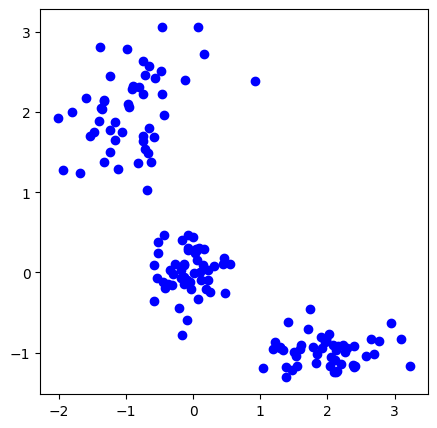

In [1]:
import numpy as np
import matplotlib.pyplot as plt


X = np.zeros((150, 2))
np.random.seed(42)

X[:50, 0] = np.random.normal(loc=0.0, scale=.3, size=50)
X[:50, 1] = np.random.normal(loc=0.0, scale=.3, size=50)

X[50:100, 0] = np.random.normal(loc=2.0, scale=.5, size=50)
X[50:100, 1] = np.random.normal(loc=-1.0, scale=.2, size=50)

X[100:150, 0] = np.random.normal(loc=-1.0, scale=.5, size=50)
X[100:150, 1] = np.random.normal(loc=2.0, scale=.5, size=50)

plt.figure(figsize=(5, 5))
plt.plot(X[:, 0], X[:, 1], 'bo')

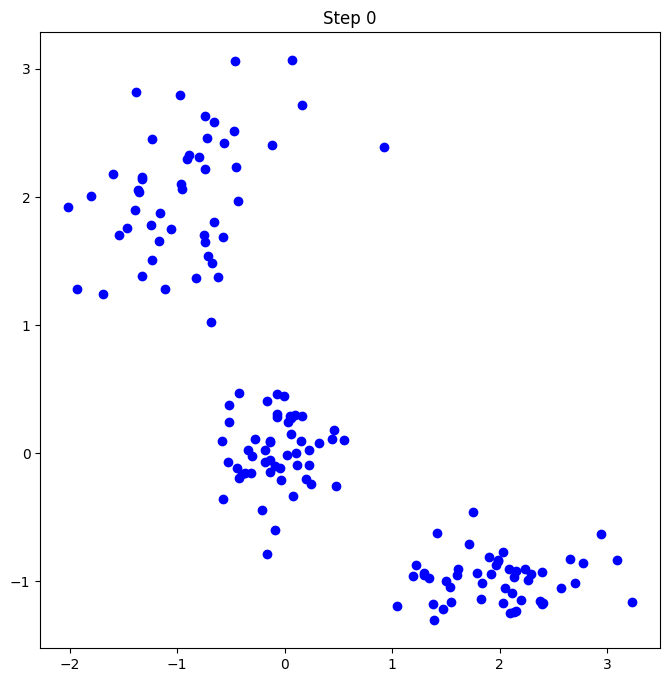

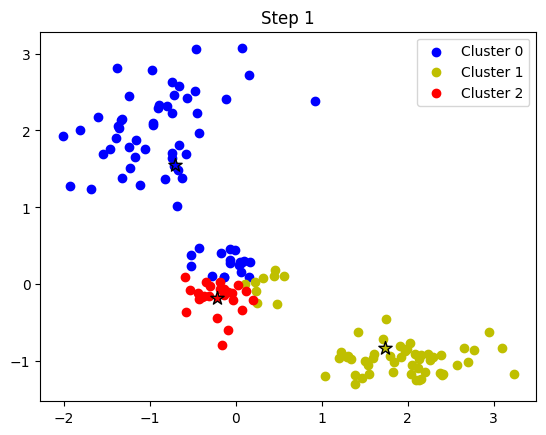

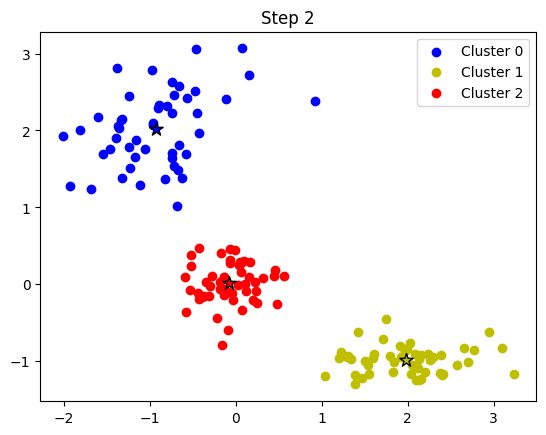

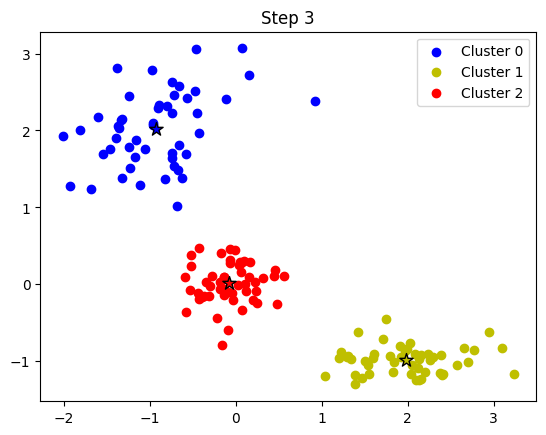

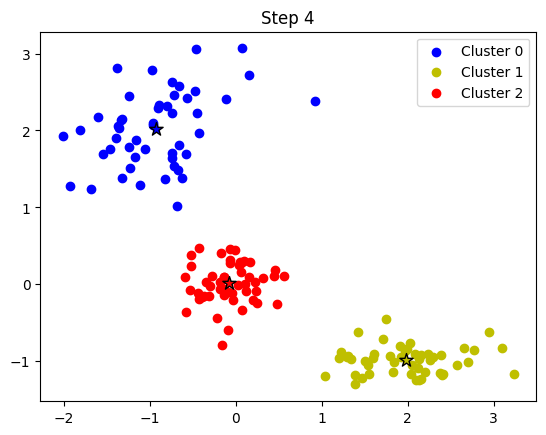

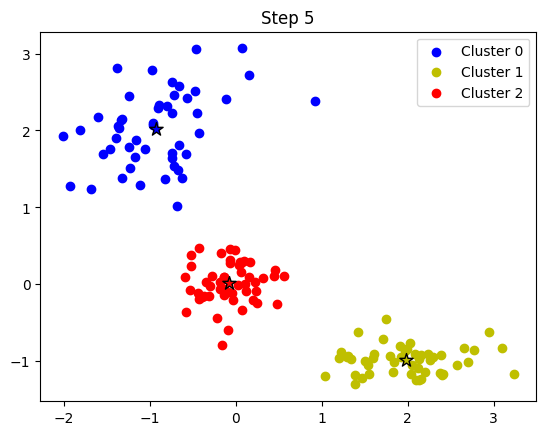

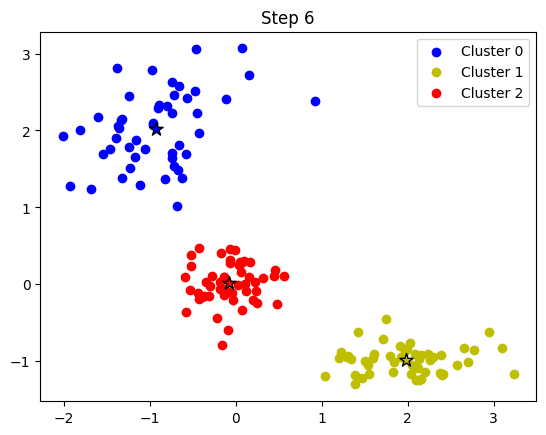

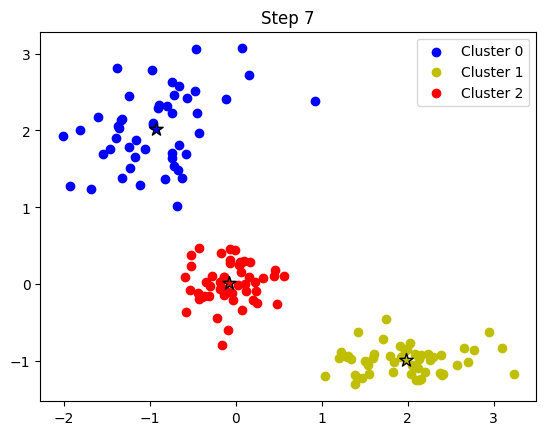

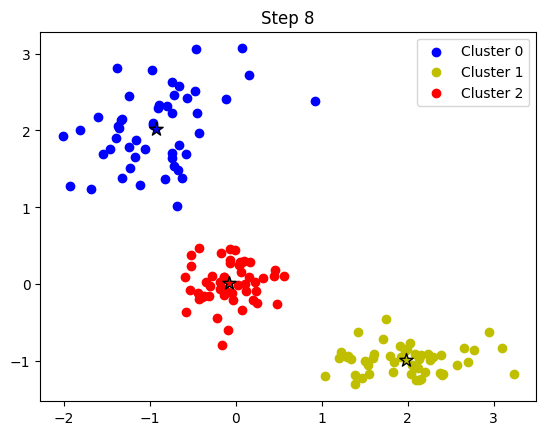

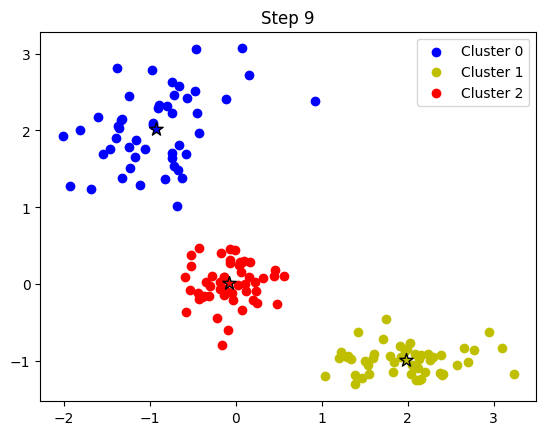

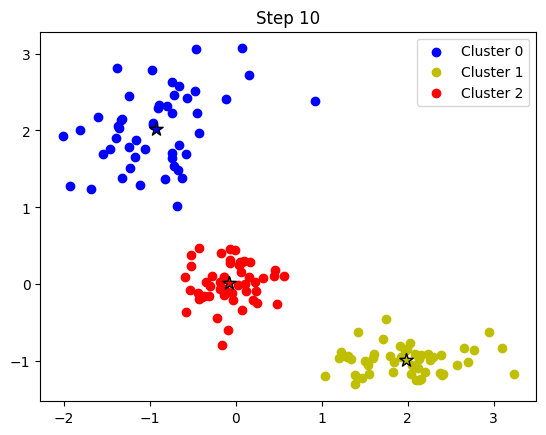

In [4]:
# Импорт функции для расчёта расстояния между двумя точками
from scipy.spatial.distance import cdist


M = 3 # Number of clasters


centroids = np.random.normal(loc=0.0, scale=.1, size=M * 2)
centroids = centroids.reshape((M, 2))


cent_history = []
cent_history.append(centroids)

fig, ax = plt.subplots(figsize=(8, 8))

plt.scatter(X[:, 0], X[:, 1], marker='o', c='b')
plt.title('Step 0')
plt.draw()
plt.pause(0.01)
color = ['b', 'y', 'r', 'c', 'm', 'k', 'g']
N = 10 # Number o iterations
for i in range(N):
    distances = cdist(X, centroids)
    labels = distances.argmin(axis=1)
    unic_labels = np.unique(labels)

    centroids = centroids.copy()
    for j in range(M):
        if j in unic_labels:
            centroids[j, :] = np.mean(X[labels == j, :], axis=0)
            plt.scatter(X[labels == j, 0], X[labels == j, 1], marker='o', label='Cluster ' + str(j), c=color[j])
            plt.scatter(centroids[j, 0], centroids[j, 1], marker='*', s=100, c=color[j], edgecolors='black')

    cent_history.append(centroids)
    plt.title('Step {:}'.format(i + 1))
    plt.legend()
    plt.draw()
    plt.pause(0.01)


Text(0, 0.5, '$Error$')

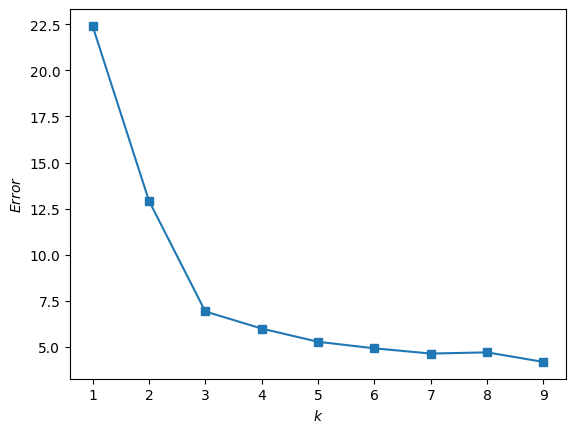

In [8]:
from sklearn.cluster import KMeans


inertia = [] # List for errors
for k in range(1, 10):
    # random state = 1 -> генерация центроидов фиксированная
    kmeans = KMeans(n_clusters=k, random_state=1).fit(X)
    inertia.append(np.sqrt(kmeans.inertia_))

plt.plot(range(1, 10), inertia, marker='s')
plt.xlabel('$k$')
plt.ylabel('$Error$')

Посмотрим на метрики для классификации

In [13]:
from time import time
from sklearn import metrics
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA 
# PCA - метод анализа главных компонентов (уменьшение размерности признаков)
# является линейным алгоритмом
from sklearn.preprocessing import scale


np.random.seed(42)

X_digits, y_digits = load_digits(return_X_y=True)
data = scale(X_digits)

n_samples, n_features = data.shape
n_digits = len(np.unique(y_digits))
labels = y_digits

samples_size = 300

print('n_digits %d, \t n_samples %d, \t n_features %d' % (n_digits, n_samples, n_features))

print(82 * '_')
print('init\t\ttime\tinertia\thomo\tcompl\tv-meas\tARI\tAMI\tsilhoette')

def bench_k_means(estimator, name, data):
    t0 = time()
    estimator.fit(data)
    print('%-9s\t%.2fs\t%i\t%.3f\t%.3f\t%.3f\t%.3f\t%.3f\t%.3f'
        % (name, (time() - t0), estimator.inertia_,
           metrics.homogeneity_score(labels, estimator.labels_),
           metrics.completeness_score(labels, estimator.labels_),
           metrics.v_measure_score(labels, estimator.labels_),
           metrics.adjusted_rand_score(labels, estimator.labels_),
           metrics.adjusted_mutual_info_score(labels, estimator.labels_),
           metrics.silhouette_score(data, estimator.labels_, metric='euclidean', sample_size=samples_size)
           ))

bench_k_means(KMeans(init='k-means++', n_clusters=n_digits, n_init=10),
              name='k-means++', data=data)
bench_k_means(KMeans(init='random', n_clusters=n_digits, n_init=10),
              name='random', data=data)
pca = PCA(n_components=n_digits).fit(data)
bench_k_means(KMeans(init=pca.components_, n_clusters=n_digits, n_init=1),
              name='PCA-based', data=data)
print(82 * '_')

n_digits 10, 	 n_samples 1797, 	 n_features 64
__________________________________________________________________________________
init		time	inertia	homo	compl	v-meas	ARI	AMI	silhoette
k-means++	0.07s	69813	0.650	0.694	0.671	0.534	0.668	0.123
random   	0.03s	69607	0.599	0.647	0.622	0.473	0.618	0.142
PCA-based	0.00s	71018	0.675	0.725	0.699	0.548	0.696	0.129
__________________________________________________________________________________


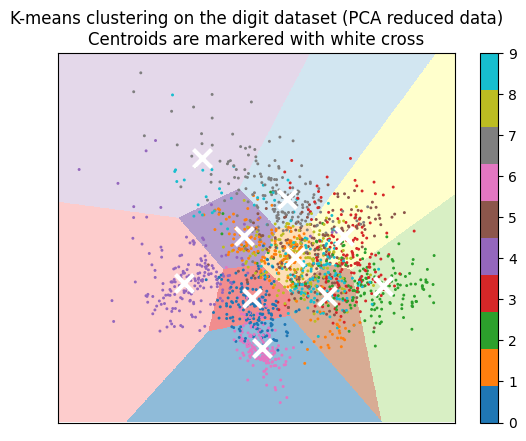

In [37]:
reduced_data = PCA(n_components=2).fit_transform(data)
kmeans = KMeans(init='k-means++', n_clusters=n_digits, n_init=10)
kmeans.fit(reduced_data)

h = .02

x_min, x_max = reduced_data[:, 0].min() - 1, reduced_data[:, 0].max() + 1
y_min, y_max = reduced_data[:, 1].min() - 1, reduced_data[:, 1].max() + 1


xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

Z = kmeans.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
plt.figure(1)
plt.clf()

plt.imshow(Z, interpolation='nearest',
           extent=(xx.min(), xx.max(), yy.min(), yy.max()),
           cmap=plt.cm.Paired,
           aspect='auto', origin='lower', alpha=.5)

centroids = kmeans.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1],
            marker='x', s=169, linewidths=3,
            color='w', zorder=10)

digitN = labels

plt.scatter(reduced_data[:, 0], reduced_data[:, 1],
            marker='.', s=5, c=digitN, cmap='tab10')

plt.title('K-means clustering on the digit dataset (PCA reduced data)\n' \
'Centroids are markered with white cross')

plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.xticks(())
plt.yticks(())
plt.colorbar()
plt.show()

Иерархическая кластеризация

In [39]:
source_ML = 'D:\\MIREA\\DPO\\Learning\\ML_School'

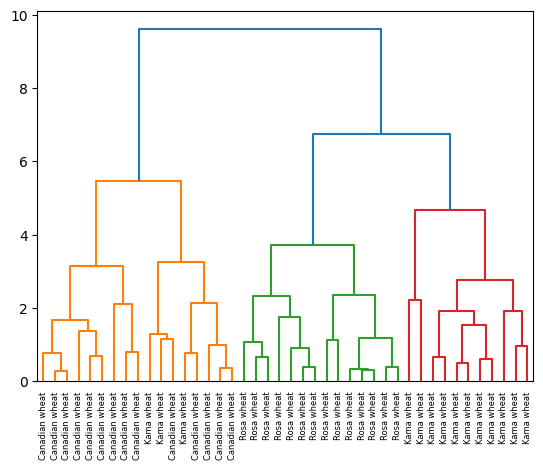

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram
import pandas as pd


seeds_df = pd.read_csv(source_ML + '/seeds-less-rows.csv')

varieties = list(seeds_df.pop('grain_variety'))

samples = seeds_df.values

mergings = linkage(samples, method='complete')

dendrogram(mergings, 
           labels=varieties,
           leaf_rotation=90,
           leaf_font_size=6,
           color_threshold=6)

plt.show()

DBSCAN

Кластеры находит самостоятельно, но необходимо задавать необходимую плотность (радиус) для обнаружения кластера иначе шум

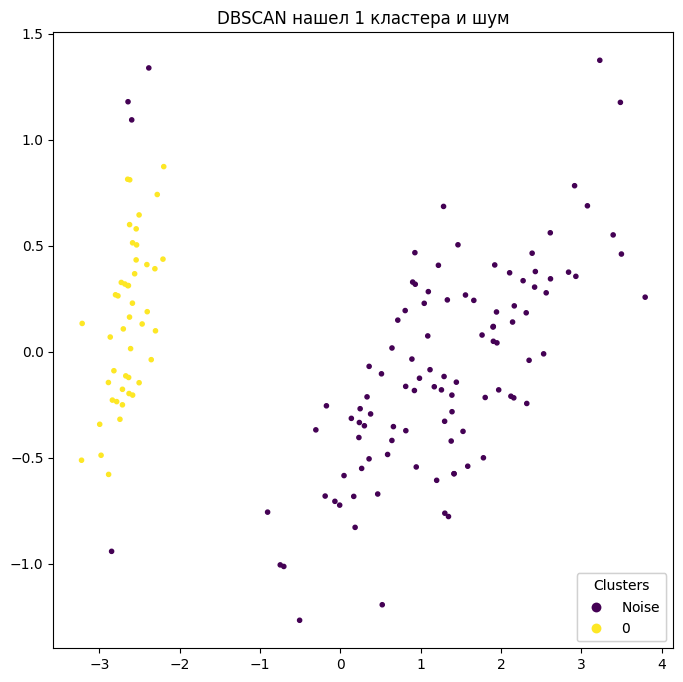

In [55]:
from sklearn.datasets import load_iris
from sklearn.cluster import DBSCAN


iris = load_iris()
dbscan = DBSCAN(eps=.5, min_samples=20)
dbscan.fit(iris.data)

pca = PCA(n_components=2).fit(iris.data)
pca_2d = pca.transform(iris.data)

N_cluster = dbscan.labels_.max() + 1
if_noise = np.count_nonzero(dbscan.labels_==-1)

fig, ax = plt.subplots(figsize=(8, 8))
scatter = ax.scatter(pca_2d[:, 0], pca_2d[:, 1], 
                     c=dbscan.labels_, 
                     marker='.')

handles, labels = scatter.legend_elements()

if if_noise:
    labels[0] = '$\\mathdefault{Noise}$'

legend1 = ax.legend(handles=handles, labels=labels,
                    loc='lower right', title='Clusters')
ax.add_artist(legend1)

if if_noise:
    plt.title('DBSCAN нашел {:} кластера и шум'.format(N_cluster))
else:
    plt.title('DBSCAN нашел {:} кластера без шума'.format(N_cluster))

plt.show()

Очень чувствителен к гиперпараметрам, статичен, но требует ресурсов, как динамические

Дополнительное задание
1. Ознакомиться с алгоритмами динамической кластеризации t-SNE и UMAP
2. Выберете набор данных и сравните работу статических и динамических моделей